# T03 Greeks
## Simulación de Procesos Financieros

Ximena Muñoz

21/09/2026

### Objetivo

Analizar cómo las sensibilidades de una opción (Greeks) permiten
entender el comportamiento de su precio ante cambios en:

- Precio del activo
- Volatilidad
- Paso del tiempo

Posteriormente, se comparará una aproximación basada en Greeks con
el valor obtenido mediante Black-Scholes y una simulación Monte Carlo
de 10,000 escenarios.

Finalmente, se analizarán los errores de la aproximación y sus
implicaciones para la toma de decisiones financieras.

## 1. Observación inicial

Antes de realizar cualquier simulación, se analizan las sensibilidades
de las tres opciones para identificar cómo respondería cada una ante
diferentes condiciones de mercado.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
opciones = pd.DataFrame({
    "Opción": ["A", "B", "C"],
    "K": [90, 100, 120],
    "T": [1/12, 3/12, 1],
    "Prima": [12, 8, 5],
    "Delta": [0.85, 0.50, 0.20],
    "Vega": [0.05, 0.25, 0.40],
    "Theta": [-0.10, -0.03, -0.01]
})

opciones

,Opción,K,T,Prima,Delta,Vega,Theta
0,A,90,0.083333,12,0.85,0.05,-0.10
1,B,100,0.250000,8,0.50,0.25,-0.03
2,C,120,1.000000,5,0.20,0.40,-0.01


### Interpretación

- **Delta** mide la sensibilidad del precio de la opción ante cambios en
  el precio de la acción.
- **Vega** mide la sensibilidad ante cambios en la volatilidad.
- **Theta** mide el efecto del paso del tiempo sobre el valor de la opción.
  Un Theta más negativo implica un deterioro más rápido del valor,
  manteniendo lo demás constante.

### 1. ¿Cuál opción parece más sensible al precio de la acción?

La **Opción A**, porque tiene el Delta más alto (0.85). Esto significa
que su precio responde más fuertemente a cambios en el precio de la acción.

### 2. ¿Cuál opción parece más sensible a cambios en volatilidad?

La **Opción C**, porque tiene el Vega más alto (0.40).

### 3. ¿Cuál opción parece deteriorarse más rápidamente con el paso del tiempo?

La **Opción A**, porque tiene el Theta más negativo (-0.10).

### 4. ¿Cuál opción parece tener el comportamiento más parecido al de la acción?

La **Opción A**, porque su Delta de 0.85 es el más cercano a 1.

### 5. ¿Cuál opción parece depender más de que ocurra un evento importante en el futuro?

La **Opción C**, porque tiene el Vega más alto (0.40), por lo que su valor
es más sensible a cambios en la volatilidad esperada.

# 2. Escenarios de mercado

Las decisiones se basan en las sensibilidades observadas en la Parte 1.
No se realiza simulación en esta sección.

### Escenario A — Aumento gradual del precio

**Compraría: Opción A**

La Opción A tiene el Delta más alto (0.85), por lo que presenta una mayor
sensibilidad ante aumentos en el precio de la acción. Además, su Vega es
bajo, lo cual es consistente con el supuesto de que la volatilidad no
cambiará significativamente.

**Evitaría: Opción C**

Su Delta es menor (0.20), por lo que responde menos directamente a un
aumento gradual del precio.

### Escenario B — Anuncio de un nuevo producto

**Compraría: Opción C**

El anuncio podría generar un cambio importante en la incertidumbre del
mercado. La Opción C tiene el Vega más alto (0.40), por lo que es la más
sensible a cambios en la volatilidad.

**Evitaría: Opción A**

Su Vega es solamente 0.05, por lo que es menos sensible a cambios en
volatilidad.

### Escenario C — Acción estable

**Compraría: Opción C**

Tiene el Theta menos negativo (-0.01), por lo que su deterioro por el paso
del tiempo es el menor de las tres. En un escenario sin movimiento del
precio, esto la hace la menos costosa de mantener.

**Evitaría: Opción A**

Su Theta es -0.10, el más negativo de las tres, por lo que pierde valor
más rápidamente con el paso del tiempo si no ocurre un movimiento
favorable en la acción.

### Escenario D — Caída significativa

Ninguna de las tres opciones es una apuesta directa a la baja, ya que las tres
tienen Delta positivo (payoff de una Call: max(S_T - K, 0)). Sin embargo,
eligiendo entre las tres:

**Compraría: Opción C**

Tiene el Delta más bajo (0.20), por lo que es la que menos valor perdería
ante una caída del precio de la acción. Es la opción "menos mala" si me
viera obligada a mantener una Call en este escenario.

**Evitaría: Opción A**

Su Delta es el más alto (0.85), por lo que sería la que más valor perdería
si el precio cae, al ser la más sensible a movimientos en el precio del
subyacente.

### Escenario E — Incertidumbre futura subestimada

**Compraría: Opción C**

La Opción C tiene el Vega más alto (0.40), por lo que su precio es el más
sensible ante un aumento de la volatilidad.

**Evitaría: Opción A**

Su Vega es solamente 0.05, por lo que presenta una menor sensibilidad a
un aumento de la volatilidad.

# 3. Simulación

Se analiza la evolución mensual de una opción Call con:

- Precio de ejercicio: K = 100
- Tasa libre de riesgo: r = 5%
- Valor inicial de la opción: 6.8887
- Delta = 0.5977
- Gamma = 0.02736
- Vega = 0.2814
- Theta = -8.116 anualizado

La aproximación mediante Greeks se actualiza utilizando:

V_t = V_(t-1) + Delta(dS) + 1/2 Gamma(dS)^2
      + Vega(dσ) + Theta(dt)

donde:

dS = S_t - S_(t-1)

dσ = σ_t - σ_(t-1)

dt = 1/12

In [3]:
# Parámetros iniciales

r = 0.05
K = 100
dt = 1 / 12

V0 = 6.8887
delta = 0.5977
gamma = 0.02736
vega = 0.2814
theta = -8.116

In [4]:
datos = pd.DataFrame({
    "Mes": ["Mayo", "Junio", "Julio", "Agosto", "Septiembre", "Octubre"],
    "Precio": [100, 102, 101, 105, 103, 110],
    "Volatilidad": [0.20, 0.25, 0.30, 0.28, 0.22, 0.20]
})

datos

,Mes,Precio,Volatilidad
0,Mayo,100,0.20
1,Junio,102,0.25
2,Julio,101,0.30
3,Agosto,105,0.28
4,Septiembre,103,0.22
5,Octubre,110,0.20


In [5]:
datos["dS"] = datos["Precio"].diff()
datos["dSigma"] = datos["Volatilidad"].diff()

datos

,Mes,Precio,Volatilidad,dS,dSigma
0,Mayo,100,0.20,NaN,NaN
1,Junio,102,0.25,2.0,0.05
2,Julio,101,0.30,-1.0,0.05
3,Agosto,105,0.28,4.0,-0.02
4,Septiembre,103,0.22,-2.0,-0.06
5,Octubre,110,0.20,7.0,-0.02


In [6]:
valores_greeks = [V0]

for i in range(1, len(datos)):
    dS = datos.loc[i, "dS"]
    dSigma = datos.loc[i, "dSigma"]

    V_nuevo = (
        valores_greeks[-1]
        + delta * dS
        + 0.5 * gamma * dS**2
        + vega * dSigma
        + theta * dt
    )

    valores_greeks.append(V_nuevo)

datos["Valor Greeks"] = valores_greeks

datos

,Mes,Precio,Volatilidad,dS,dSigma,Valor Greeks
0,Mayo,100,0.20,NaN,NaN,6.888700
1,Junio,102,0.25,2.0,0.05,7.476557
2,Julio,101,0.30,-1.0,0.05,6.230273
3,Agosto,105,0.28,4.0,-0.02,8.157992
4,Septiembre,103,0.22,-2.0,-0.06,6.324095
5,Octubre,110,0.20,7.0,-0.02,10.496353


### Interpretación de la aproximación con Greeks

La tabla anterior muestra cómo evoluciona el valor de la opción si asumimos
que Delta, Gamma, Vega y Theta permanecen constantes en sus valores de mayo.
El mayor salto en `dS` ocurre en octubre (+7), y el mayor cambio en `dSigma`
ocurre en junio y julio (+0.05 en ambos). Estos son los meses donde
esperaríamos que la aproximación se aleje más del valor real, ya que las
sensibilidades verdaderas de la opción cambian junto con el precio y la
volatilidad, pero aquí las mantenemos fijas.

## Valor de la opción mediante Black-Scholes

Para comparar la aproximación mediante Greeks, calculamos el valor de una
Call mediante el modelo de Black-Scholes.

El tiempo al vencimiento disminuye conforme avanzan los meses.

In [7]:
from statistics import NormalDist

N = NormalDist().cdf

def black_scholes_call(S, K, r, sigma, T):
    d1 = (
        np.log(S / K) + (r + 0.5 * sigma**2) * T
    ) / (sigma * np.sqrt(T))

    d2 = d1 - sigma * np.sqrt(T)

    call = (
        S * N(d1)
        - K * np.exp(-r * T) * N(d2)
    )

    return call

In [8]:
datos["Tiempo restante"] = np.array([6, 5, 4, 3, 2, 1]) / 12

datos["Black-Scholes"] = [
    black_scholes_call(
        S=datos.loc[i, "Precio"],
        K=K,
        r=r,
        sigma=datos.loc[i, "Volatilidad"],
        T=datos.loc[i, "Tiempo restante"]
    )
    for i in range(len(datos))
]

datos

,Mes,Precio,Volatilidad,dS,dSigma,Valor Greeks,Tiempo restante,Black-Scholes
0,Mayo,100,0.20,NaN,NaN,6.888700,0.500000,6.888729
1,Junio,102,0.25,2.0,0.05,7.476557,0.416667,8.662111
2,Julio,101,0.30,-1.0,0.05,6.230273,0.333333,8.286009
3,Agosto,105,0.28,4.0,-0.02,8.157992,0.250000,9.341809
4,Septiembre,103,0.22,-2.0,-0.06,6.324095,0.166667,5.852960
5,Octubre,110,0.20,7.0,-0.02,10.496353,0.083333,10.520232


### Interpretación: Greeks vs Black-Scholes

Al comparar ambas columnas se nota que en mayo (mes inicial) los dos métodos
coinciden casi exactamente, lo cual es esperado porque los Greeks se
calcularon justo para ese punto de partida. Conforme avanzan los meses,
la aproximación con Greeks se separa del valor de Black-Scholes, ya que
depende de qué tanto cambiaron el precio y la volatilidad respecto a mayo.

## Simulación Monte Carlo

Como complemento, se simulan 10,000 posibles precios finales para cada
mes utilizando el precio y la volatilidad correspondientes.

El valor de la Call se obtiene como el promedio de los payoffs descontados.

In [9]:
def monte_carlo_call(S, K, r, sigma, T, n_sim=10000, seed=42):
    rng = np.random.default_rng(seed)

    Z = rng.standard_normal(n_sim)

    ST = S * np.exp(
        (r - 0.5 * sigma**2) * T
        + sigma * np.sqrt(T) * Z
    )

    payoff = np.maximum(ST - K, 0)

    precio = np.exp(-r * T) * np.mean(payoff)

    return precio

In [10]:
datos["Monte Carlo (10,000)"] = [
    monte_carlo_call(
        S=datos.loc[i, "Precio"],
        K=K,
        r=r,
        sigma=datos.loc[i, "Volatilidad"],
        T=datos.loc[i, "Tiempo restante"]
    )
    for i in range(len(datos))
]

datos

,Mes,Precio,Volatilidad,dS,dSigma,Valor Greeks,Tiempo restante,Black-Scholes,"Monte Carlo (10,000)"
0,Mayo,100,0.20,NaN,NaN,6.888700,0.500000,6.888729,6.815729
1,Junio,102,0.25,2.0,0.05,7.476557,0.416667,8.662111,8.573885
2,Julio,101,0.30,-1.0,0.05,6.230273,0.333333,8.286009,8.197247
3,Agosto,105,0.28,4.0,-0.02,8.157992,0.250000,9.341809,9.262800
4,Septiembre,103,0.22,-2.0,-0.06,6.324095,0.166667,5.852960,5.803394
5,Octubre,110,0.20,7.0,-0.02,10.496353,0.083333,10.520232,10.465127


In [11]:
datos["Error MC vs BS"] = np.abs(datos["Monte Carlo (10,000)"] - datos["Black-Scholes"])
datos[["Mes", "Black-Scholes", "Monte Carlo (10,000)", "Error MC vs BS"]].round(4)

,Mes,Black-Scholes,"Monte Carlo (10,000)",Error MC vs BS
0,Mayo,6.8887,6.8157,0.0730
1,Junio,8.6621,8.5739,0.0882
2,Julio,8.2860,8.1972,0.0888
3,Agosto,9.3418,9.2628,0.0790
4,Septiembre,5.8530,5.8034,0.0496
5,Octubre,10.5202,10.4651,0.0551


El error entre Black-Scholes y Monte Carlo es consistentemente pequeño
(menor a unos cuantos centavos), lo cual confirma que la simulación de
10,000 escenarios converge bien al valor teórico. Esto nos da confianza en
que las diferencias observadas entre **Greeks** y **Black-Scholes** no se
deben a errores de simulación, sino a la limitación propia de aproximar
el valor de la opción usando sensibilidades fijas.

In [14]:
datos["Error absoluto"] = np.abs(datos["Valor Greeks"] - datos["Black-Scholes"])

comparacion = datos[
    ["Mes", "Valor Greeks", "Black-Scholes", "Error absoluto"]
].rename(columns={"Valor Greeks": "Greeks", "Error absoluto": "Error Absoluto"})

comparacion.round(4)

,Mes,Greeks,Black-Scholes,Error Absoluto
0,Mayo,6.8887,6.8887,0.0000
1,Junio,7.4766,8.6621,1.1856
2,Julio,6.2303,8.2860,2.0557
3,Agosto,8.1580,9.3418,1.1838
4,Septiembre,6.3241,5.8530,0.4711
5,Octubre,10.4964,10.5202,0.0239


### Interpretación

La diferencia entre ambos métodos representa el error de utilizar los
Greeks iniciales como aproximación durante toda la trayectoria. Un error
pequeño indica que la aproximación sigue cercana al valor de Black-Scholes,
mientras que un error mayor indica que las condiciones del mercado se
alejaron más del punto inicial.

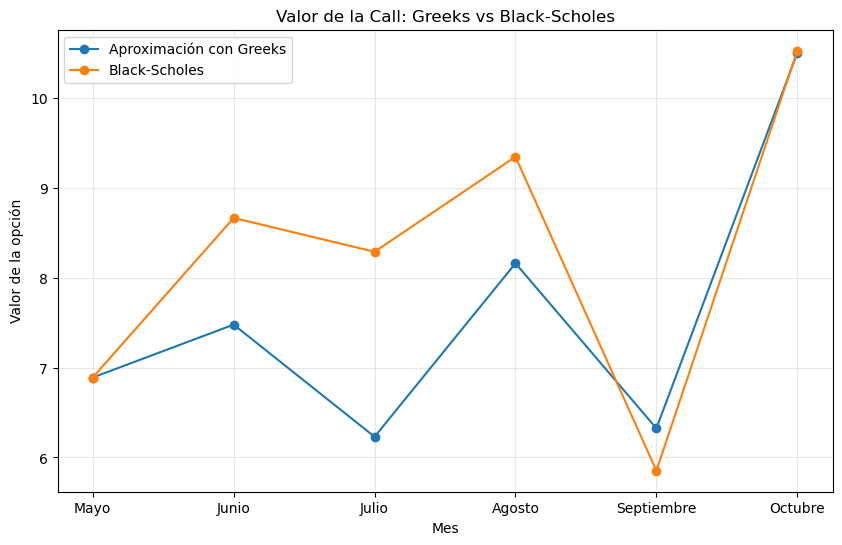

In [13]:
plt.figure(figsize=(10, 6))

plt.plot(
    datos["Mes"],
    datos["Valor Greeks"],
    marker="o",
    label="Aproximación con Greeks"
)

plt.plot(
    datos["Mes"],
    datos["Black-Scholes"],
    marker="o",
    label="Black-Scholes"
)

plt.xlabel("Mes")
plt.ylabel("Valor de la opción")
plt.title("Valor de la Call: Greeks vs Black-Scholes")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# 4. Análisis de resultados

### 1. ¿Los Greeks iniciales describen con precisión toda la trayectoria?

No completamente. La aproximación mediante Greeks parte de los valores
iniciales de Delta, Gamma, Vega y Theta y los utiliza para actualizar el
valor de la opción. Sin embargo, estas sensibilidades también cambian
cuando cambian el precio de la acción, la volatilidad y el tiempo.

Por esta razón, la aproximación puede alejarse del valor obtenido con
Black-Scholes, especialmente después de movimientos importantes.

### 2. ¿En qué mes apareció el error más grande?

El mayor error aparece en **julio**, con un error absoluto aproximado de
**2.06**.

### 3. ¿Qué factor parece contribuir más al error?

El error parece estar relacionado principalmente con los cambios en el precio y la volatilidad, junto con el paso del tiempo. En particular, entre mayo y julio la volatilidad aumenta de 20% a 30%, mientras que el precio también cambia. Como los Greeks utilizados permanecen fijos en sus valores iniciales, las sensibilidades reales de la opción pueden alejarse de las utilizadas en la aproximación.

### 4. ¿Por qué los Greeks funcionan mejor para movimientos pequeños que para movimientos grandes?

Los Greeks proporcionan una aproximación local del cambio en el precio
de la opción. Para movimientos pequeños, esta aproximación es razonable.

Cuando los movimientos son grandes, la relación entre las variables deja
de estar bien representada por una aproximación basada en sensibilidades
iniciales, por lo que el error aumenta.

Gamma ayuda a capturar parte de la curvatura respecto al precio, pero
Delta, Vega y Theta también cambian a lo largo del tiempo.

### 5. Si la trayectoria fuera mucho más volátil, ¿esperarías errores menores?

No. Esperaría errores potencialmente mayores.

Una trayectoria más volátil produciría cambios más grandes en el precio
y posiblemente en la volatilidad. Como la aproximación utiliza los
Greeks iniciales, movimientos más grandes pueden alejar el valor
aproximado del valor obtenido mediante Black-Scholes.

### 6. Conclusión

Los Greeks son herramientas útiles para medir la sensibilidad de una
opción y realizar aproximaciones rápidas ante cambios relativamente
pequeños. Sin embargo, no describen perfectamente una trayectoria
completa porque las propias sensibilidades cambian conforme evolucionan
el precio, la volatilidad y el tiempo.

En este ejercicio, la mayor diferencia entre la aproximación con Greeks
y Black-Scholes se presentó en julio. Esto muestra que, cuando las
condiciones de mercado cambian de manera importante, es conveniente
utilizar un modelo de valoración completo en lugar de depender
únicamente de las sensibilidades iniciales.